# VK Clips Recommender

In [86]:
%pip install implicit

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix

from implicit.als import AlternatingLeastSquares
from implicit.nearest_neighbours import CosineRecommender, bm25_weight

## I. Исследование датасета

Данные взяты из открытого датасета взаимодействий пользователей с VK клипами VK-LSVD (https://huggingface.co/datasets/deepvk/VK-LSVD).

### i. Загрузка датасета

In [88]:
train = pd.read_parquet('data/train.parquet')
test = pd.read_parquet('data/test.parquet')

train.head()

,user_id,item_id,place,platform,agent,timespent,like,dislike,share,bookmark,click_on_author,open_comments
0,141827770,160593626,1,1,1,56,False,False,False,False,False,False
1,494341617,402842289,1,0,0,11,False,False,False,False,False,False
2,453833313,102672169,0,0,0,45,False,False,False,False,False,False
3,154047442,139795075,1,0,0,39,False,False,False,False,False,False
4,330326695,232077218,1,0,0,57,False,False,False,False,False,False


Датасет содержит следующие признаки:

* `user_id`, тип uint32 — уникальный идентификатор пользователя.
* `item_id`, тип uint32 — уникальный идентификатор клипа.
* `place`, тип uint8 — место взаимодействия с клипом (лента, поиск, группа и др.; 24 категории).
* `platform`, тип uint8 — платформа просмотра (Android, Web, TV и др.; 11 категорий).
* `agent`, тип uint8 — тип клиента (браузер, приложение и др.; 29 категорий).
* `timespent`, тип uint8 — время просмотра клипа в секундах (от 0 до 255).
* `like`, тип bool — наличие лайка.
* `dislike`, тип bool — наличие дизлайка.
* `share`, тип bool — факт отправки клипа другим пользователям.
* `bookmark`, тип bool — добавление клипа в закладки.
* `click_on_author`, тип bool — переход на страницу автора клипа.
* `open_comments`, тип bool — открытие комментариев к клипу.

In [89]:
train.shape, test.shape

((1904581, 12), (1309342, 12))

In [90]:
len(set(test['user_id']) - set(train['user_id']))

0

In [91]:
len(set(test['item_id']) - set(train['item_id']))

2923

### ii. Анализ пользователей и клипов

Теперь исследуем самих пользователей и клипы из обучающего датасета. Посчитаем количество уникальных идентификаторов:

In [92]:
n_users = train['user_id'].nunique()
n_items = train['item_id'].nunique()

n_users, n_items

(8531, 3729)

Посчитаем для каждого пользователя количество взаимодействий.

In [93]:
user_activity = train.groupby('user_id').size()
user_activity.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,0
count,8531.000000
mean,223.254132
std,82.359659
min,71.000000
25%,159.000000
50%,211.000000
75%,275.000000
90%,336.000000
95%,377.000000
99%,453.700000


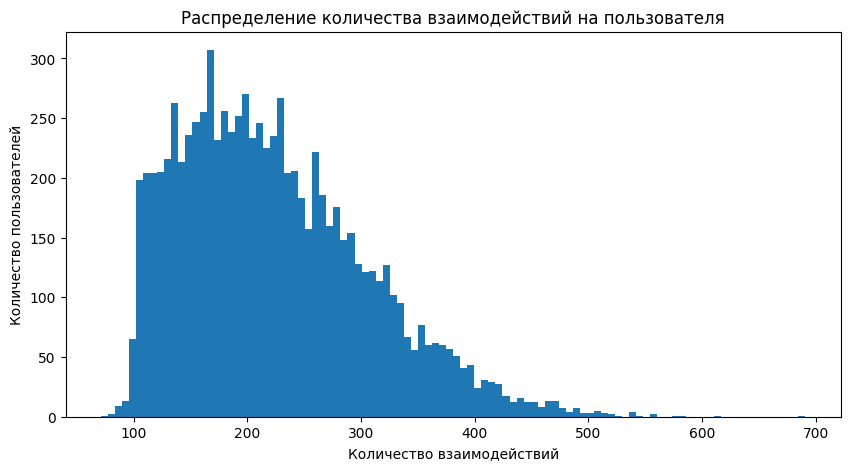

In [94]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(user_activity, bins=100)

ax.set_title('Распределение количества взаимодействий на пользователя')
ax.set_xlabel('Количество взаимодействий')
ax.set_ylabel('Количество пользователей')

plt.show()

Аналогично, посчитаем количество взаимодействий с каждым клипом.

In [95]:
item_popularity = train.groupby('item_id').size()
item_popularity.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,0
count,3729.000000
mean,510.748458
std,514.717043
min,106.000000
25%,193.000000
50%,323.000000
75%,621.000000
90%,1137.400000
95%,1570.000000
99%,2484.880000


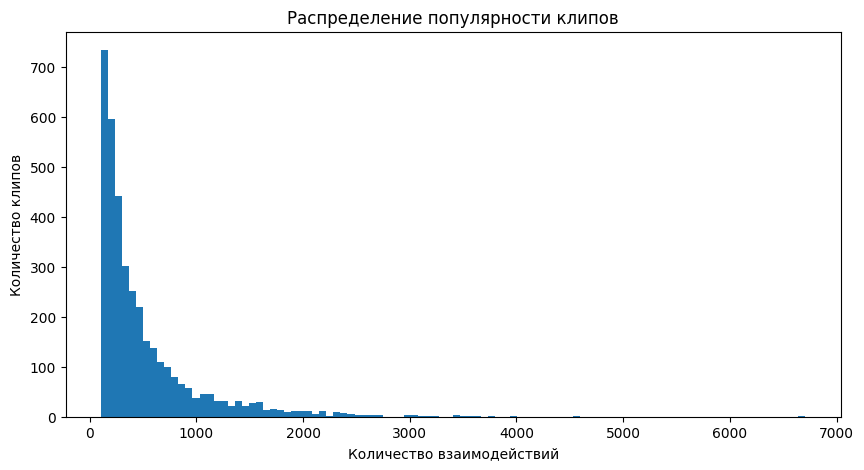

In [96]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(item_popularity, bins=100)

ax.set_title('Распределение популярности клипов')
ax.set_xlabel('Количество взаимодействий')
ax.set_ylabel('Количество клипов')

plt.show()

### iii. Анализ времени просмотра и пользовательских действий

Проанализируем как долго пользователи смотрят клип и как часто совершают дополнительные действия при просмотре.

In [97]:
train['timespent'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(2)

,timespent
count,1904581.00
mean,31.08
std,32.48
min,6.00
25%,10.00
50%,19.00
75%,41.00
90%,69.00
95%,92.00
99%,165.00


In [98]:
actions = [
    'like',
    'dislike',
    'share',
    'bookmark',
    'click_on_author',
    'open_comments'
]

In [99]:
action_rates = train[actions].mean().sort_values(ascending=False)
pd.DataFrame({'Action': action_rates.index, 'Percentage (%)': action_rates.values * 100})

,Action,Percentage (%)
0,open_comments,2.771371
1,like,1.576462
2,share,0.452540
3,click_on_author,0.212960
4,bookmark,0.066996
5,dislike,0.042109


Пользователи редко совершают дополнительные действия и чаще совершают положительные, чем отрицательные.

Поссмотрим насколько различные действия связаны между собой.

In [100]:
behavior = ['timespent'] + actions
corr = train[behavior].corr()
corr.round(3)

,timespent,like,dislike,share,bookmark,click_on_author,open_comments
timespent,1.000,0.061,0.006,0.074,0.026,0.039,0.168
like,0.061,1.000,0.000,0.059,0.060,0.014,0.045
dislike,0.006,0.000,1.000,-0.001,0.003,0.001,0.009
share,0.074,0.059,-0.001,1.000,0.027,0.007,0.032
bookmark,0.026,0.060,0.003,0.027,1.000,0.006,0.015
click_on_author,0.039,0.014,0.001,0.007,0.006,1.000,0.031
open_comments,0.168,0.045,0.009,0.032,0.015,0.031,1.000


### iv. Анализ контекстных признаков

Проанализируем признаки `place`, `platform`, `agent` и их распределения.

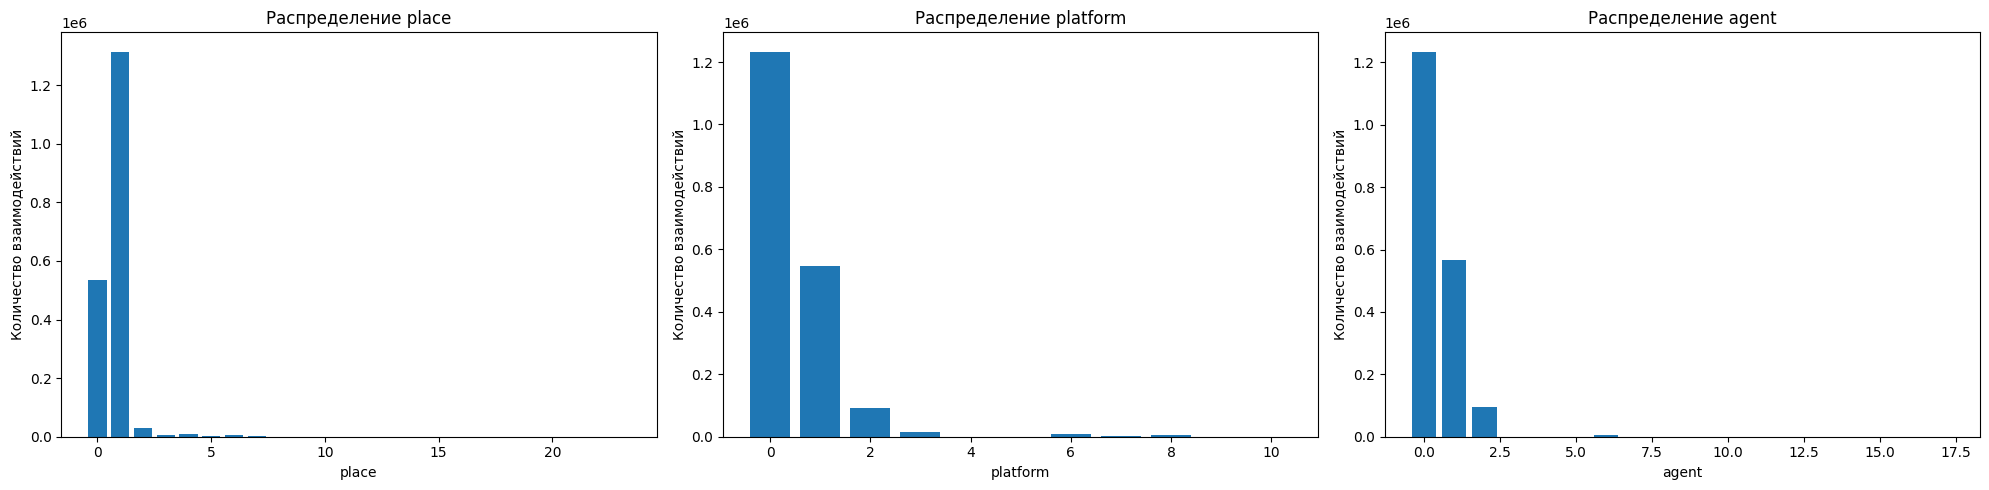

In [101]:
contexts = ['place', 'platform', 'agent']

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, col in zip(axes, contexts):
    counts = train[col].value_counts().sort_index()

    ax.bar(counts.index, counts.values)

    ax.set_title(f'Распределение {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Количество взаимодействий')

plt.tight_layout()
plt.show()

### v. Разреженность матрицы взаимодействий

Рассмотрим разреженность матрицы взаимодействий пользователей и клипов. Плотность матрицы определяется как отношение количества известных пар пользователь–клип к общему количеству возможных пар.

In [102]:
pairs = train[['user_id', 'item_id']].drop_duplicates()

n_pairs = len(pairs)
density = n_pairs / (n_users * n_items)

print(f'Плотность: {density:.2%}')
print(f'Разреженность: {1 - density:.2%}')

Плотность: 5.99%
Разреженность: 94.01%


## II. Baseline

Бейзлайн, предложенный соревнованием, реализует простой подход на основе популярности клипов. Список рекомендаций одинаковый для всех пользователей и не учитывает их индивидуальные предпочтения.

In [103]:
!python solution_toppop.py --input_path data/train.parquet --output_path submission_baseline.csv

Compute recommendations. It may take a few minutes.
Recommendations computed.
Save result to file submission_baseline.csv.
File saved.


Порог (результат бейзлайна), который нужно преодалеть, `1.3`.

## III. Построение рекомендательной системы (iALS)

iALS - метод матричной факторизации для неявной обратной связи.

#### Матричная факторизация

Матрица взаимодействий приближается произведением двух матриц:

$$R \approx PQ^T$$

где:

* $R\in\mathbb{R}^{n\times m}$ - матрица взаимодействий пользователей и клипов;
* $P\in\mathbb{R}^{n\times k}$ - матрица латентных факторов пользователей;
* $Q\in\mathbb{R}^{m\times k}$ - матрица латентных факторов клипов;
* $k\ll\min(n,m)$ - размерность латентного пространства.

#### Предсказание

Предсказанная оценка взаимодействия пользователя $u$ с клипом $i$:

$$\hat{a}_{ui} = p_u^Tq_i$$

Предпочтение пользователя:

$$a_{ui}=\mathbb{1}[s_{ui}>0]$$

Уверенность в предпочтении:

$$
c_{ui}=
\begin{cases}
|s_{ui}|, & s_{ui}\neq 0,\\
1, & s_{ui}=0.
\end{cases}
$$

где $s_{ui}$ — значение взаимодействия.

#### Функция потерь

$$
\mathcal L(P,Q)=
\sum_{u,i}c_{ui}(a_{ui}-p_u^\top q_i)^2+ \lambda\left(
\sum_u\|p_u\|_2^2+
\sum_i\|q_i\|_2^2
\right)
$$

где $\lambda$ - коэффициент регуляризации.

Обучение выполняется методом Alternating Least Squares: поочерёдно фиксируется одна матрица латентных факторов и оптимизируется другая.

#### Сила и значение взаимодействия

Для нашей задачи определим силу взаимодействия следующим образом:

$$
\begin{aligned}
r_{ui}={}&w_0+w_t\frac{\log(1+t_{ui})}{\log(256)}
+w_l\,like_{ui}\\
&+w_s\,share_{ui}+w_b\,bookmark_{ui}\\
&+w_a\,click_{ui}+w_c\,comments_{ui}.
\end{aligned}
$$

Тогда значение взаимодействия:

$$
s_{ui}=
\begin{cases}
1+\alpha r_{ui}, & dislike_{ui}=0,\\
-(1+\alpha r_{ui}), & dislike_{ui}=1,\\
0, & \text{взаимодействие отсутствует},
\end{cases}
$$

где $\alpha$ — гиперпараметр.

### i. Веса взаимодействий

In [104]:
alpha = 10

weights = {
    'view': 1,
    'time': 1,
    'like': 3,
    'share': 4,
    'bookmark': 2,
    'click_on_author': 2,
    'open_comments': 1
}

r_ui = (
    weights['view']
    + weights['time'] * np.log(1 + train['timespent']) / np.log(256)
    + weights['like'] * train['like'].astype(int)
    + weights['share'] * train['share'].astype(int)
    + weights['bookmark'] * train['bookmark'].astype(int)
    + weights['click_on_author'] * train['click_on_author'].astype(int)
    + weights['open_comments'] * train['open_comments'].astype(int)
)

s_ui = np.where(train['dislike'], -(1 + alpha * r_ui), 1 + alpha * r_ui)

### ii. Матрица взаимодействий

In [105]:
user_id_to_idx = {user_id: idx for idx, user_id in enumerate(train['user_id'].unique())}
item_id_to_idx = {item_id: idx for idx, item_id in enumerate(train['item_id'].unique())}

user_idx = train['user_id'].map(user_id_to_idx).to_numpy()
item_idx = train['item_id'].map(item_id_to_idx).to_numpy()

In [106]:
R = csr_matrix(
    (s_ui, (user_idx, item_idx)),
    shape=(len(user_id_to_idx), len(item_id_to_idx))
)

R.sum_duplicates()
R.eliminate_zeros()

R.shape

(8531, 3729)

In [107]:
R.nnz / (R.shape[0] * R.shape[1]), 1 - R.nnz / (R.shape[0] * R.shape[1])

(0.0598697055481941, 0.9401302944518058)

### iii. Обучение iALS

In [108]:
ials = AlternatingLeastSquares(
    factors=64,
    regularization=0.1,
    iterations=20,
    calculate_training_loss=True,
    random_state=42
)

ials.fit(R)

  0%|          | 0/20 [00:00<?, ?it/s]

In [109]:
P = ials.user_factors
Q = ials.item_factors

P.shape, Q.shape

((8531, 64), (3729, 64))

### iv. Генерация рекомендаций

In [110]:
idx_to_item_id = {idx: item_id for item_id, idx in item_id_to_idx.items()}

recommendations = []

for user_id, user_idx in user_id_to_idx.items():
    item_indices, scores = ials.recommend(
        userid=user_idx,
        user_items=R[user_idx],
        N=10,
        filter_already_liked_items=True
    )

    for item_idx, score in zip(item_indices, scores):
        recommendations.append({
            'user_id': user_id,
            'recs': idx_to_item_id[item_idx]
        })

submission = pd.DataFrame(recommendations)

In [111]:
submission.to_csv('submission.csv', index=False)
submission.head()

,user_id,recs
0,141827770,513208552
1,141827770,478850705
2,141827770,173868696
3,141827770,172777680
4,141827770,184565195


### v. Оценка модели

Результат iALS в AllCups:

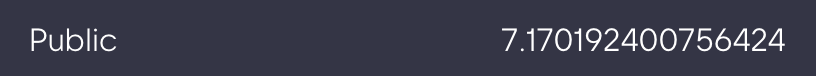

## IV. Построение рекомендательной системы (itemKNN)

ItemKNN (Item-based k-Nearest Neighbors) - метод коллабортивной фильтрации, основанный на сходстве объектов, в нашем случае - клипов.

#### Матрица взаимодействий

Рассмотрим матрицу взаимодействий пользователей и клипов $R\in\mathbb{R}^{n\times m}$.

Каждый клип представляется вектором взаимодействий пользователей:

$$s_i=(s_{1i},s_{2i},\ldots,s_{ni})^T.$$

#### Сходство клипов

Для определения сходства двух клипов используется косинусная мера:

$$
sim(i,j)=
\frac{s_i^Ts_j}
{|s_i|_2|s_j|_2}.
$$

Чем выше значение $sim(i,j)$, тем более похожими считаются клипы $i$ и $j$ с точки зрения взаимодействий пользователей.

#### Поиск ближайших соседей

Для каждого клипа $i$ выбираются $K$ наиболее похожих клипов:

$$
N_K(i)=\operatorname{TopK}_{j\neq i}sim(i,j),
$$

где $K$ - количество ближайших соседей.

#### Предсказание

Предсказанная оценка взаимодействия пользователя $u$ с клипом $i$ вычисляется на основе его взаимодействий с похожими клипами:

$$
\hat s_{ui}=
\sum_{j\in N_K(i)\cap H_u}sim(i,j)s_{uj}
$$

где:

* $H_u$ — множество клипов, с которыми взаимодействовал пользователь $u$;
* $N_K(i)$ — множество ближайших соседей клипа $i$;
* $sim(i,j)$ — сходство клипов $i$ и $j$.

#### Сила взаимодействия

Для учёта различных действий пользователя используется взвешенная оценка:

$$
\begin{aligned}
r_{ui}={}&w_0+w_t\frac{\log(1+t_{ui})}{\log(256)}
+w_l\,like_{ui}\\
&+w_s\,share_{ui}+w_b\,bookmark_{ui}\\
&+w_a\,click_{ui}+w_c\,comments_{ui}.
\end{aligned}
$$

Отрицательная обратная связь учитывается изменением знака взаимодействия:


$$
s_{ui}=
\begin{cases}
r_{ui}, & dislike_{ui}=0,\\
-r_{ui}, & dislike_{ui}=1,\\
0, & \text{взаимодействие отсутствует},
\end{cases}
$$

#### Формирование рекомендаций

Для каждого пользователя вычисляются оценки клипов, отсутствующих в его истории взаимодействий. Итоговый список рекомендаций формируется выбором 10 клипов с наибольшими предсказанными оценками.

### i. Веса взаимодействий

In [112]:
weights = {
    'view': 1,
    'time': 1,
    'like': 3,
    'share': 4,
    'bookmark': 2,
    'click_on_author': 2,
    'open_comments': 1
}

r_ui = (
    weights['view']
    + weights['time'] * np.log(1 + train['timespent']) / np.log(256)
    + weights['like'] * train['like'].astype(int)
    + weights['share'] * train['share'].astype(int)
    + weights['bookmark'] * train['bookmark'].astype(int)
    + weights['click_on_author'] * train['click_on_author'].astype(int)
    + weights['open_comments'] * train['open_comments'].astype(int)
)

s_ui = np.where(train['dislike'], -r_ui, r_ui)

### ii. Матрица взаимодействий

In [113]:
user_id_to_idx = {user_id: idx for idx, user_id in enumerate(train['user_id'].unique())}
item_id_to_idx = {item_id: idx for idx, item_id in enumerate(train['item_id'].unique())}

user_idx = train['user_id'].map(user_id_to_idx).to_numpy()
item_idx = train['item_id'].map(item_id_to_idx).to_numpy()

In [114]:
R = csr_matrix(
    (s_ui, (user_idx, item_idx)),
    shape=(len(user_id_to_idx), len(item_id_to_idx))
)

R.sum_duplicates()
R.eliminate_zeros()

R.shape

(8531, 3729)

In [115]:
R.nnz / (R.shape[0] * R.shape[1]), 1 - R.nnz / (R.shape[0] * R.shape[1])

(0.0598697055481941, 0.9401302944518058)

### iii. Обучение itemKNN

In [116]:
itemknn = CosineRecommender(K=100)
itemknn.fit(R)

/usr/local/lib/python3.13/dist-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.009772777557373047 seconds
  warnings.warn(


  0%|          | 0/3729 [00:00<?, ?it/s]

### iv. Генерация рекомендаций

In [117]:
idx_to_item_id = {idx: item_id for item_id, idx in item_id_to_idx.items()}

recommendations = []

for user_id, user_idx in user_id_to_idx.items():
    item_indices, scores = itemknn.recommend(
        userid=user_idx,
        user_items=R[user_idx],
        N=10,
        filter_already_liked_items=True
    )

    for item_idx, score in zip(item_indices, scores):
        recommendations.append({
            'user_id': user_id,
            'recs': idx_to_item_id[item_idx]
        })

submission = pd.DataFrame(recommendations)

In [118]:
submission.to_csv('submission.csv', index=False)
submission.head()

,user_id,recs
0,141827770,434650826
1,141827770,160269283
2,141827770,178221643
3,141827770,377181597
4,141827770,449807352


### v. Оценка модели



Результат itemKNN:

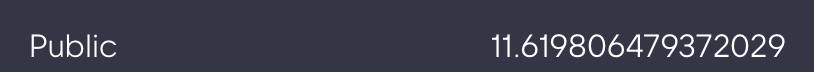